## Establish statistical baselines for single player and multi-player datasets.

### Install packages/libraries

In [1]:
# !pip install nba_api pandas numpy scikit-learn matplotlib seaborn jupyter requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import time
from pathlib import Path

from nba_api.stats.endpoints import playergamelog
from nba_api.stats.static import players
from sklearn.metrics import brier_score_loss, accuracy_score

from sklearn.calibration import calibration_curve

Single player

In [17]:
csv_path = Path(r"C:\Users\16827\Documents\nba-llm-calibration\data\processed\single_player.csv")
df = pd.read_csv(csv_path)
df["GAME_DATE"] = pd.to_datetime(df["GAME_DATE"])

Historical-frequency baseline without training a machine learning model. Our model looks at Luka's previous 10 games and calculates how often he scored 25+ points.

In [3]:
eval_df = df.dropna(
    subset=["PTS_25_RATE_L10", "TARGET_25"]
).copy()

brier = brier_score_loss(
    eval_df["TARGET_25"],
    eval_df["PTS_25_RATE_L10"]
)

print(f"Historical Frequency Brier Score: {brier:.4f}")

Historical Frequency Brier Score: 0.1261


Compare against a constant-probability baseline. Note that the historical frequency Brier is a **diagnostic comparison**, not a realistic prediction model yet. We calculated its probability using the outcomes we're evaluating.

In [4]:
actual = eval_df["TARGET_25"]
predicted = eval_df["PTS_25_RATE_L10"]

# Historical frequency model
historical_brier = brier_score_loss(actual, predicted)

# Constant probability benchmark
base_rate = actual.mean()
constant_predictions = np.full(len(actual), base_rate)

constant_brier = brier_score_loss(
    actual,
    constant_predictions
)

print(f"Number of games: {len(actual)}")
print(f"Actual 25+ scoring rate: {base_rate:.2%}")
print(f"Historical Frequency Brier: {historical_brier:.4f}")
print(f"Constant Probability Brier: {constant_brier:.4f}")

Number of games: 54
Actual 25+ scoring rate: 88.89%
Historical Frequency Brier: 0.1261
Constant Probability Brier: 0.0988


**What we learned:** Recent 10-game scoring frequency hasn't demonstrated better probability predictions than simply using Luka's overall scoring tendency.

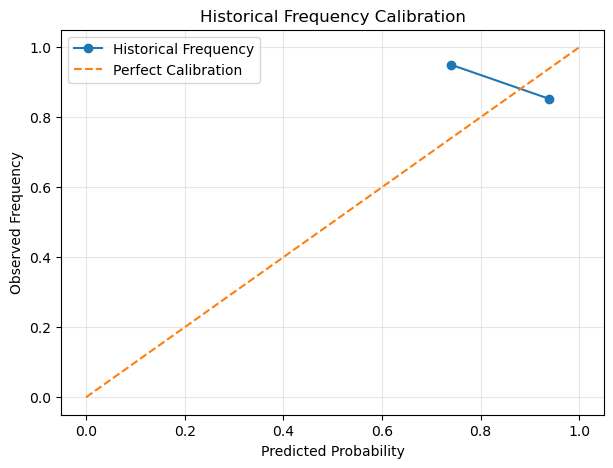

In [5]:
prob_true, prob_pred = calibration_curve(
    actual,
    predicted,
    n_bins=5,
    strategy="uniform"
)

plt.figure(figsize=(7, 5))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Historical Frequency"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Predicted Probability")
plt.ylabel("Observed Frequency")
plt.title("Historical Frequency Calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

- When our model predicted approximately 73% probability of Luka scoring 25+, he actually did so about 95% of the time.
    - The model underestimated his likelihood of reaching 25 points.
- When our model predicted approximately 94%, Luka actually reached 25 points about 85% of the time.
    - The model overestimated his likelihood.

In [6]:
calibration_df = eval_df[
    ["PTS_25_RATE_L10", "TARGET_25"]
].copy()

calibration_df["bin"] = pd.cut(
    calibration_df["PTS_25_RATE_L10"],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    include_lowest=True
)

calibration_summary = (
    calibration_df
    .groupby("bin", observed=True)
    .agg(
        count=("TARGET_25", "size"),
        mean_predicted=("PTS_25_RATE_L10", "mean"),
        actual_frequency=("TARGET_25", "mean")
    )
)

print(calibration_summary)

            count  mean_predicted  actual_frequency
bin                                                
(0.6, 0.8]     20        0.740000          0.950000
(0.8, 1.0]     34        0.938235          0.852941


In [7]:
def expected_calibration_error(y_true, y_prob, n_bins=5):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(y_prob, bin_edges[1:-1], right=True)

    ece = 0.0

    for i in range(n_bins):
        mask = bin_ids == i

        if mask.sum() == 0:
            continue

        avg_confidence = y_prob[mask].mean()
        actual_frequency = y_true[mask].mean()

        ece += (mask.sum() / len(y_true)) * abs(
            avg_confidence - actual_frequency
        )

    return ece


actual = eval_df["TARGET_25"]
predicted = eval_df["PTS_25_RATE_L10"]

ece = expected_calibration_error(actual, predicted, n_bins=5)

print(f"Expected Calibration Error: {ece:.4f}")

Expected Calibration Error: 0.1315


Our predicted probabilities differed from actual scoring frequencies by about 13 percentage points on average.

Multi-player

In [18]:
csv_path = Path(r"C:\Users\16827\Documents\nba-llm-calibration\data\processed\multi_player.csv")
df = pd.read_csv(csv_path)
df["GAME_DATE"] = pd.to_datetime(df["GAME_DATE"])

In [14]:
def historical_over_rate(group):
    group = group.copy()

    points = group["PTS"].to_numpy()
    lines = group["PROP_LINE"].to_numpy()

    probabilities = np.full(len(group), np.nan)

    for i in range(10, len(group)):
        if np.isnan(lines[i]):
            continue

        previous_points = points[i-10:i]
        current_line = lines[i]

        probabilities[i] = np.mean(
            previous_points > current_line
        )

    group["HIST_OVER_RATE_L10"] = probabilities

    return group


df = (
    df.groupby("PLAYER_ID", group_keys=False)
    .apply(historical_over_rate)
)

C:\Users\16827\AppData\Local\Temp\ipykernel_14536\2154661846.py:27: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(historical_over_rate)


Evaluate our baseline

In [15]:
eval_df = df.dropna(
    subset=[
        "PROP_LINE",
        "TARGET_OVER",
        "HIST_OVER_RATE_L10"
    ]
).copy()

actual = eval_df["TARGET_OVER"].astype(int)
predicted = eval_df["HIST_OVER_RATE_L10"]

brier = brier_score_loss(actual, predicted)

accuracy = accuracy_score(
    actual,
    (predicted >= 0.5).astype(int)
)

ece = expected_calibration_error(
    actual,
    predicted,
    n_bins=5
)

print(f"Total observations: {len(eval_df)}")
print(f"Over rate: {actual.mean():.2%}")
print(f"Historical Frequency Brier: {brier:.4f}")
print(f"Historical Frequency ECE: {ece:.4f}")
print(f"Classification Accuracy: {accuracy:.2%}")

Total observations: 461
Over rate: 49.02%
Historical Frequency Brier: 0.2590
Historical Frequency ECE: 0.0868
Classification Accuracy: 48.81%


#### Create chronolgical splits.

In [16]:
eval_df = eval_df.sort_values(
    ["GAME_DATE", "PLAYER_ID"]
).reset_index(drop=True)

# Use game dates as split boundaries
unique_dates = sorted(eval_df["GAME_DATE"].unique())

train_end = int(len(unique_dates) * 0.60)
cal_end = int(len(unique_dates) * 0.80)

train_dates = unique_dates[:train_end]
cal_dates = unique_dates[train_end:cal_end]
test_dates = unique_dates[cal_end:]

train_df = eval_df[eval_df["GAME_DATE"].isin(train_dates)].copy()
cal_df = eval_df[eval_df["GAME_DATE"].isin(cal_dates)].copy()
test_df = eval_df[eval_df["GAME_DATE"].isin(test_dates)].copy()

for name, subset in [
    ("Train", train_df),
    ("Calibration", cal_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {len(subset)} observations, "
        f"{subset['GAME_DATE'].min().date()} to "
        f"{subset['GAME_DATE'].max().date()}"
    )

Train: 283 observations, 2025-11-09 to 2026-02-05
Calibration: 91 observations, 2026-02-06 to 2026-03-13
Test: 87 observations, 2026-03-14 to 2026-04-12


Download data

In [26]:
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

train_df.to_csv(output_dir / "train.csv", index=False)
cal_df.to_csv(output_dir / "calibration.csv", index=False)
test_df.to_csv(output_dir / "test.csv", index=False)

Evaluate the historical-frequency baseline on each split.

In [19]:
def evaluate_baseline(data):
    actual = data["TARGET_OVER"].astype(int)
    predicted = data["HIST_OVER_RATE_L10"]

    return {
        "Observations": len(data),
        "Over Rate": actual.mean(),
        "Brier Score": brier_score_loss(actual, predicted),
        "ECE": expected_calibration_error(
            actual, predicted, n_bins=5
        ),
        "Accuracy": accuracy_score(
            actual, (predicted >= 0.5).astype(int)
        )
    }

results = pd.DataFrame({
    "Train": evaluate_baseline(train_df),
    "Calibration": evaluate_baseline(cal_df),
    "Test": evaluate_baseline(test_df)
}).T

display(results.round(4))

,Observations,Over Rate,Brier Score,ECE,Accuracy
Train,283.0,0.4664,0.2602,0.0951,0.4841
Calibration,91.0,0.5165,0.2602,0.0901,0.4725
Test,87.0,0.5402,0.2539,0.0563,0.5172


Establish a fair constant-probability baseline.

In [22]:
train_over_rate = train_df["TARGET_OVER"].mean()

print(f"Training Over Rate: {train_over_rate:.2%}")

constant_results = {}

for name, subset in [
    ("Train", train_df),
    ("Calibration", cal_df),
    ("Test", test_df)
]:
    actual = subset["TARGET_OVER"].astype(int)

    predictions = np.full(
        len(subset),
        train_over_rate
    )

    constant_results[name] = {
        "Brier Score": brier_score_loss(
            actual, predictions
        ),
        "ECE": expected_calibration_error(
            actual, predictions, n_bins=5
        )
    }

display(pd.DataFrame(constant_results).T.round(4))

Training Over Rate: 46.64%


,Brier Score,ECE
Train,0.2489,0.0000
Calibration,0.2522,0.0501
Test,0.2538,0.0738
